# Análise de Cancelamento de Clientes (Churn) — Terra Signal

Neste projeto, organizamos os dados dos clientes da **Terra Signal** para entender quem são nossos assinantes, o que eles contratam e o que os leva a cancelar os serviços.

### Perguntas que vamos responder:
1. Qual é o sentimento geral dos clientes em relação aos serviços da empresa?
2. O tipo de contrato influencia diretamente na taxa de cancelamento?
3. Quais formas de pagamento são mais comuns na carteira e como elas se relacionam com a permanência?
4. Como o feedback escrito (sentimento negativo ou positivo) reflete o risco de saída do cliente?

## 1. Preparação e Leitura dos Dados (Camada Bronze)
Nesta primeira etapa, carregamos as ferramentas necessárias e abrimos a base original (`history.csv`) exatamente como ela veio do sistema, sem alterações.

### Bibliotecas utilizadas
Importamos o `pandas` para manipular as tabelas e o `matplotlib` / `seaborn` para montar os gráficos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("history.csv")

### Explorando os dados brutos
Olhamos as primeiras e últimas linhas da tabela para conferir se a leitura funcionou bem e identificar possíveis problemas logo de cara.

In [3]:
#primeira vizualização do dataframe
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691
5,6797-LNAQX,Male,0,Yes,Yes,70,Yes,Yes,Fiber optic,No,...,Yes,Yes,Two year,No,Bank transfer (automatic),98.30,6859.50,Yes,I have been a customer with this company for 7...,5487
6,3050-GBUSH,Female,0,No,No,3,no,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Credit card (automatic),34.80,113.95,No,I have been a customer with this DSL internet ...,6382
7,8020-BWHYL,Female,1,No,No,15,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Credit card (automatic),75.30,NaN,Yes,I recently canceled my service with this provi...,353
8,6752-APNJL,Male,0,Yes,Yes,42,Yes,No,DSL,Yes,...,No,No,Month-to-month,No,Mailed check,54.50,2301.15,No,I have been a customer with this company for 4...,2436
9,1760-CAZHT,Male,0,No,Yes,25,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,20.80,460.20,No,I have been a customer with this company for 2...,7049


In [4]:
df.tail(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
5624,8869-LIHMK,Female,0,No,No,64,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),115.10,7334.05,No,I have been a loyal customer of this company f...,5342
5625,0932-YIXYU,Female,0,No,No,47,yes,No,No,No internet service,...,No internet service,No internet service,Two year,No,Credit card (automatic),20.25,1029.80,No,I have been a customer with this company for a...,9229
5626,3569-EDBPQ,Female,0,No,No,24,Yes,Yes,Fiber optic,Yes,...,No,No,Month-to-month,Yes,Electronic check,84.35,1938.05,No,I have been a customer with this fiber optic i...,7165
5627,8645-KOMJQ,Male,0,Yes,Yes,69,Yes,Yes,DSL,No,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),81.95,5601.40,No,I have been a loyal customer with this company...,411
5628,0786-IVLAW,Female,1,No,No,66,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Bank transfer (automatic),108.10,7238.60,No,I have been a customer with this company for 6...,5113
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904
5633,3915-ODIYG,Male,1,No,No,60,Yes,Yes,DSL,Yes,...,No,Yes,One year,Yes,Electronic check,71.75,4374.55,No,I have been a loyal customer of this internet ...,3016


### O que significa cada coluna
Abaixo está o resumo do que cada campo representa na base original:

| Coluna           | Tradução                 | Definição resumida                                        |
| ---------------- | ------------------------ | --------------------------------------------------------- |
| customerID       | ID do cliente            | Código único de identificação do cliente.                 |
| gender           | Gênero                   | Gênero do cliente.                                        |
| SeniorCitizen    | Cidadão idoso            | Indica se o cliente é idoso (1 = sim, 0 = não).           |
| Partner          | Parceiro(a)              | Indica se o cliente possui companheiro(a).                |
| Dependents       | Dependentes              | Indica se o cliente possui dependentes.                   |
| tenure           | Tempo de permanência     | Tempo de relacionamento com a empresa, em meses.          |
| PhoneService     | Serviço telefônico       | Indica se o cliente possui telefone contratado.           |
| MultipleLines    | Múltiplas linhas         | Indica se possui mais de uma linha telefônica.            |
| InternetService  | Serviço de internet      | Tipo de serviço de internet contratado.                   |
| OnlineSecurity   | Segurança online         | Indica se possui serviço de segurança digital.            |
| OnlineBackup     | Backup online            | Indica se possui cópia de segurança de arquivos na nuvem. |
| DeviceProtection | Proteção de dispositivos | Indica se possui proteção para seus dispositivos.         |
| TechSupport      | Suporte técnico          | Indica se possui assistência técnica contratada.          |
| StreamingTV      | Transmissão de TV        | Indica se possui serviço de streaming de televisão.       |
| StreamingMovies  | Streaming de filmes      | Indica se possui serviço de streaming de filmes.          |
| Contract         | Contrato                 | Tipo e duração do contrato do cliente.                    |
| PaperlessBilling | Faturamento sem papel    | Indica se recebe a fatura digitalmente.                   |
| PaymentMethod    | Método de pagamento      | Forma utilizada para pagar pelos serviços.                |
| MonthlyCharges   | Cobranças mensais        | Valor cobrado mensalmente pelos serviços.                 |
| TotalCharges     | Cobranças totais         | Valor total acumulado cobrado do cliente.                 |
| Churn            | Cancelamento             | Indica se o cliente cancelou o serviço.                   |
| CustomerFeedback | Feedback do cliente      | Comentário do cliente sobre sua experiência.              |
| MonthlyIncome    | Renda mensal             | Valor da renda mensal do cliente.                         |

### Verificando a estrutura da tabela
Checamos o tamanho da base (5.634 clientes), os formatos de cada coluna e onde existem campos vazios.

In [5]:
df.dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   str    
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  Paymen

## 2. Limpeza e Organização (Camada Silver)
Aqui começamos a arrumar a casa: traduzimos os nomes das colunas para português, corrigimos tipos de dados errados e preenchemos informações faltantes.

### Traduzindo os nomes das colunas
Deixamos todas as colunas em português para facilitar a leitura e o trabalho do grupo.

In [6]:
dicionario_dados = {
    "Variável Original": [
        "customerID", "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
        "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
        "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
        "CustomerFeedback", "MonthlyIncome"
    ],
    "Variável Traduzida": [
        "clienteID", "genero", "idoso", "conjuge", "dependentes", "tempoDeServiço",
        "serviçoTelefonico", "multiplasLinhasTelefonicas", "serviçoDeInternet",
        "segurançaOnline", "backupOnline", "proteçaoDeDispositivo", "suporteTecnico",
        "streamingTV", "streamingDeFilmes", "contrato", "faturaDigital",
        "metodoDePagamento", "mensalidade", "totalDeEncargos", "cancelamento",
        "feedbackDoCliente", "rendaMensal"
    ]
}

traducao = dict(zip(
    dicionario_dados["Variável Original"],
    dicionario_dados["Variável Traduzida"]
))

df = df.rename(columns=traducao)

# Transforma o dicionário em um DataFrame do Pandas
df_dicionario = pd.DataFrame(dicionario_dados)

print(df_dicionario.to_string(index=False))

Variável Original         Variável Traduzida
       customerID                  clienteID
           gender                     genero
    SeniorCitizen                      idoso
          Partner                    conjuge
       Dependents                dependentes
           tenure             tempoDeServiço
     PhoneService          serviçoTelefonico
    MultipleLines multiplasLinhasTelefonicas
  InternetService          serviçoDeInternet
   OnlineSecurity            segurançaOnline
     OnlineBackup               backupOnline
 DeviceProtection      proteçaoDeDispositivo
      TechSupport             suporteTecnico
      StreamingTV                streamingTV
  StreamingMovies          streamingDeFilmes
         Contract                   contrato
 PaperlessBilling              faturaDigital
    PaymentMethod          metodoDePagamento
   MonthlyCharges                mensalidade
     TotalCharges            totalDeEncargos
            Churn               cancelamento
 CustomerF

### Ajustando o formato dos dados
Transformamos respostas de "Sim/Não" em valores lógicos (`True`/`False`), ajustamos categorias e convertemos textos numéricos (como `tempoDeServiço`) para números de verdade.

In [7]:
df["clienteID"] = df["clienteID"].astype("string")

mapa_genero = {"Male": True, "Female": False}
df["genero"] = df["genero"].map(mapa_genero).astype("bool")

mapa_idoso = {1: True, 0: False}
df["idoso"] = df["idoso"].map(mapa_idoso).astype("bool")

mapa_sim_nao = {"Yes": True, "No": False, "yes": True, "no": False}
df["conjuge"] = df["conjuge"].map(mapa_sim_nao).astype("bool")

df["dependentes"] = df["dependentes"].map(mapa_sim_nao).astype("bool")

df["tempoDeServiço"] = pd.to_numeric(
    df["tempoDeServiço"].replace("unknown", pd.NA),
    errors="coerce"
).astype("Int8")

df["serviçoTelefonico"] = df["serviçoTelefonico"].astype("category")

df["multiplasLinhasTelefonicas"] = df["multiplasLinhasTelefonicas"].astype("category")

df["serviçoDeInternet"] = df["serviçoDeInternet"].astype("category")

df["segurançaOnline"] = df["segurançaOnline"].astype("category")

df["backupOnline"] = df["backupOnline"].astype("category")

df["proteçaoDeDispositivo"] = df["proteçaoDeDispositivo"].astype("category")

df["suporteTecnico"] = df["suporteTecnico"].astype("category")

df["streamingTV"] = df["streamingTV"].astype("category")

df["streamingDeFilmes"] = df["streamingDeFilmes"].astype("category")

df["contrato"] = df["contrato"].astype("category")

df["faturaDigital"] = df["faturaDigital"].map(mapa_sim_nao).astype("bool")

df["metodoDePagamento"] = df["metodoDePagamento"].astype("category")

df["mensalidade"] = df["mensalidade"].astype("float64")

df["cancelamento"] = df["cancelamento"].map(mapa_sim_nao).astype("bool")

df["feedbackDoCliente"] = df["feedbackDoCliente"].astype("string")

df["rendaMensal"] = df["rendaMensal"].astype("int16")

### Corrigindo tempos de serviço desconhecidos
Alguns clientes estavam com o tempo de serviço marcado como "unknown". Como eles informaram há quanto tempo são clientes no próprio texto do feedback, recuperamos esses meses manualmente.

In [8]:
df.loc[1097,'tempoDeServiço'] = 48
df.loc[1791,'tempoDeServiço'] = 12
df.loc[1984,'tempoDeServiço'] = 72
df.loc[2361,'tempoDeServiço'] = 22
df.loc[2372,'tempoDeServiço'] = 1
df.loc[3837,'tempoDeServiço'] = 73
df.loc[5328,'tempoDeServiço'] = 72
df.loc[4875,'tempoDeServiço'] = 28
df.loc[1059,'tempoDeServiço'] = 72
df.loc[5324,'tempoDeServiço'] = 24
df.loc[3476,'tempoDeServiço'] = 4
df.loc[2896,'tempoDeServiço'] = 67
df.loc[3153,'tempoDeServiço'] = 64
df.loc[3388,'tempoDeServiço'] = 67
df.loc[2641,'tempoDeServiço'] = 36
df.loc[2936,'tempoDeServiço'] = 15
df.loc[2959,'tempoDeServiço'] = 67
df.loc[3300,'tempoDeServiço'] = 6
df.loc[3515,'tempoDeServiço'] = 5

### Conferindo valores vazios e inconsistências
Verificamos se ainda restam campos nulos na tabela. Encontramos 278 registros sem valor na coluna `totalDeEncargos`.

In [9]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   clienteID                   5634 non-null   string  
 1   genero                      5634 non-null   bool    
 2   idoso                       5634 non-null   bool    
 3   conjuge                     5634 non-null   bool    
 4   dependentes                 5634 non-null   bool    
 5   tempoDeServiço              5634 non-null   Int8    
 6   serviçoTelefonico           5634 non-null   category
 7   multiplasLinhasTelefonicas  5634 non-null   category
 8   serviçoDeInternet           5634 non-null   category
 9   segurançaOnline             5634 non-null   category
 10  backupOnline                5634 non-null   category
 11  proteçaoDeDispositivo       5634 non-null   category
 12  suporteTecnico              5634 non-null   category
 13  streamingTV                 5

In [10]:
df.isnull().sum()

clienteID                       0
genero                          0
idoso                           0
conjuge                         0
dependentes                     0
tempoDeServiço                  0
serviçoTelefonico               0
multiplasLinhasTelefonicas      0
serviçoDeInternet               0
segurançaOnline                 0
backupOnline                    0
proteçaoDeDispositivo           0
suporteTecnico                  0
streamingTV                     0
streamingDeFilmes               0
contrato                        0
faturaDigital                   0
metodoDePagamento               0
mensalidade                     0
totalDeEncargos               278
cancelamento                    0
feedbackDoCliente               0
rendaMensal                     0
dtype: int64

### Preenchendo o total de encargos e salvando a camada Silver
Para não perder esses 278 clientes, calculamos o valor estimado multiplicando o `tempoDeServiço` pela `mensalidade`. Depois disso, salvamos a base limpa em `df_silver.csv`.

In [11]:
# Filtra apenas as linhas onde 'tempoDeServiço' é nulo (NaN)
nulos = df['tempoDeServiço'].isnull()
nulos = df['totalDeEncargos'].isnull()

#Substituir os nulos do "TotalDeEncargos"
multiplicando = df['tempoDeServiço'] * df['mensalidade']
df['totalDeEncargos'] = df['totalDeEncargos'].fillna(multiplicando)

# Mensalidade mostra somente duas casas após o zero
df['mensalidade'] = df['mensalidade'].round(2)

# Mostra o resultado na tela
df[['tempoDeServiço', 'totalDeEncargos', 'mensalidade']]

df.isnull().sum()

clienteID                     0
genero                        0
idoso                         0
conjuge                       0
dependentes                   0
tempoDeServiço                0
serviçoTelefonico             0
multiplasLinhasTelefonicas    0
serviçoDeInternet             0
segurançaOnline               0
backupOnline                  0
proteçaoDeDispositivo         0
suporteTecnico                0
streamingTV                   0
streamingDeFilmes             0
contrato                      0
faturaDigital                 0
metodoDePagamento             0
mensalidade                   0
totalDeEncargos               0
cancelamento                  0
feedbackDoCliente             0
rendaMensal                   0
dtype: int64

In [12]:
df.to_csv("df_silver.csv", index=False, sep=",", decimal=".", encoding="utf-8-sig")

## 3. Camada Gold e análise de sentimentos
Mantenha `history.csv` e `df_silver_completo.csv` no diretório de trabalho. O VADER classifica o feedback original em inglês. Depois da classificação, o notebook incorpora o feedback em português que já vem no CSV de traduções.

### Classificando o feedback original em inglês
O VADER calcula o score de polaridade com base no texto original, incluindo a pontuação e as maiúsculas. Os comentários são classificados como positivos, neutros ou negativos. Comentários vazios recebem score zero.

In [13]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analisador = SentimentIntensityAnalyzer()
df_gold = df.copy()

def calcular_polaridade(texto):
    if pd.isna(texto) or not texto.strip():
        return 0.0
    return analisador.polarity_scores(texto)["compound"]

df_gold["score_sentimento"] = df_gold["feedbackDoCliente"].map(calcular_polaridade)
df_gold["sentimento"] = "Neutro"
df_gold.loc[df_gold["score_sentimento"] >= 0.05, "sentimento"] = "Positivo"
df_gold.loc[df_gold["score_sentimento"] <= -0.05, "sentimento"] = "Negativo"

### Incorporando o feedback em português
Associamos as traduções prontas pelo ID do cliente e salvamos o resultado em `df_gold.csv`.

In [15]:
traducoes = pd.read_csv(
    "df_silver_completo.csv",
    encoding="utf-8-sig",
    usecols=["clienteID", "feedbackDoClientePT"],
    dtype={"clienteID": "string", "feedbackDoClientePT": "string"},
)
df_gold = df_gold.merge(traducoes, on="clienteID", how="left", validate="one_to_one", indicator=True)
sem_correspondencia = df_gold["_merge"].ne("both")
if sem_correspondencia.any():
    raise ValueError(f"{sem_correspondencia.sum()} clientes sem ID correspondente no CSV de traduções.")

df_gold["feedbackDoCliente"] = df_gold.pop("feedbackDoClientePT")
df_gold = df_gold.drop(columns="_merge")


df_gold.to_csv("df_gold.csv", index=False, sep=",", decimal=".", encoding="utf-8-sig")

## 4. Análises e Respostas às Perguntas de Negócio
Abaixo respondemos às perguntas propostas utilizando gráficos e indicadores extraídos da base.

### Quantos clientes cancelaram por tipo de contrato?
O gráfico mostra o volume absoluto. A taxa por tipo de contrato aparece na seção de perfil de cancelamento.

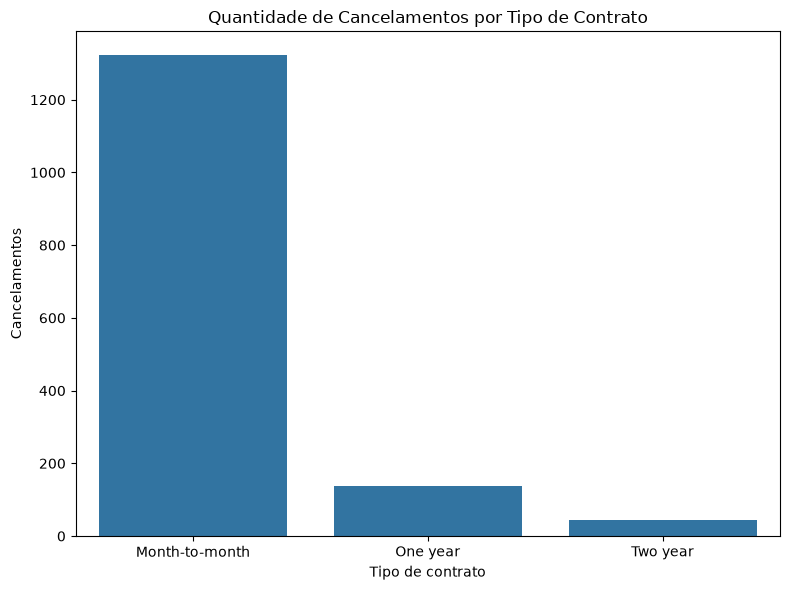

In [16]:
plt.figure(figsize=(8, 6))
cancelamentos_por_contrato = df_gold.groupby("contrato", observed=True)["cancelamento"].sum()
sns.barplot(x=cancelamentos_por_contrato.index, y=cancelamentos_por_contrato.values)
plt.title("Quantidade de Cancelamentos por Tipo de Contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Cancelamentos")
plt.tight_layout()
plt.show()

### Pergunta 3: Como estão distribuídas as formas de pagamento dos clientes?
**Resposta:** O **cheque eletrônico (`Electronic check`)** é o meio mais usado, representando **33,6%** da carteira, seguido por cheque enviado pelo correio (`Mailed check`), transferência automática e cartão de crédito automático (cada um na faixa de 21% a 23%). Nos relatos dos clientes, pagamentos manuais (como envio de cheque) aparecem como um ponto de incômodo que motiva a troca de operadora.

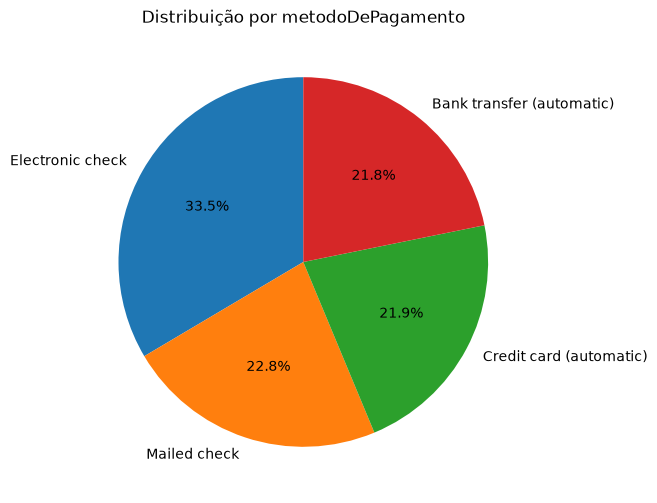

In [17]:
col_pizza = 'metodoDePagamento'
contagem = df[col_pizza].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(contagem.values, labels=contagem.index, autopct='%1.1f%%', startangle=90)
plt.title(f'Distribuição por {col_pizza}')
plt.show()

### Perfil de cancelamento
As taxas abaixo mostram a proporção de clientes que cancelaram dentro de cada grupo.

#### Tipo de contrato

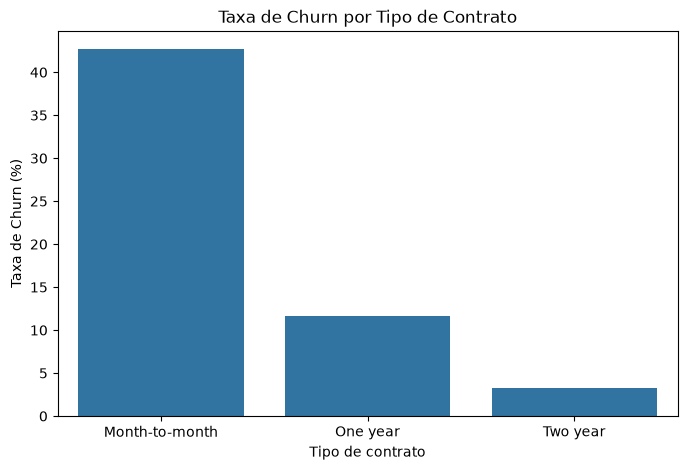

In [18]:
# Calculando a taxa utilizando as colunas traduzidas: 'contrato' e 'cancelamento'
taxa = df_gold.groupby('contrato')['cancelamento'].apply(
    lambda x: x.mean() * 100
).reset_index(name='Taxa_Churn')

plt.figure(figsize=(8, 5))
sns.barplot(data=taxa, x='contrato', y='Taxa_Churn')

plt.title('Taxa de Churn por Tipo de Contrato')
plt.xlabel('Tipo de contrato')
plt.ylabel('Taxa de Churn (%)')

plt.show()

#### Presença de dependentes

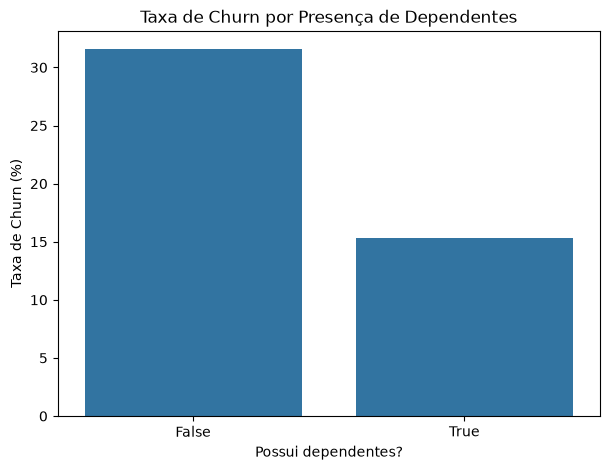

In [19]:
# Calculando a taxa de cancelamento usando as colunas traduzidas
taxa = df_gold.groupby('dependentes')['cancelamento'].apply(
    lambda x: x.mean() * 100
).reset_index(name='Taxa_Churn')

plt.figure(figsize=(7, 5))
sns.barplot(data=taxa, x='dependentes', y='Taxa_Churn')

plt.title('Taxa de Churn por Presença de Dependentes')
plt.xlabel('Possui dependentes?')
plt.ylabel('Taxa de Churn (%)')

plt.show()

#### Presença de parceiro

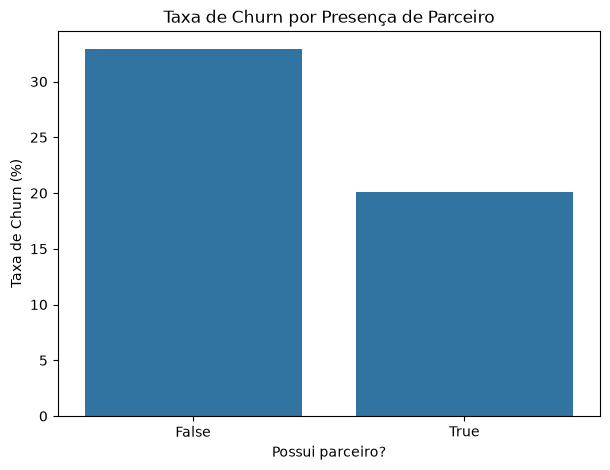

In [20]:
taxa = df_gold.groupby('conjuge')['cancelamento'].apply(
    lambda x: x.mean() * 100
).reset_index(name='Taxa_Churn')

plt.figure(figsize=(7, 5))
sns.barplot(data=taxa, x='conjuge', y='Taxa_Churn')

plt.title('Taxa de Churn por Presença de Parceiro')
plt.xlabel('Possui parceiro?')
plt.ylabel('Taxa de Churn (%)')

plt.show()

#### Serviço de internet

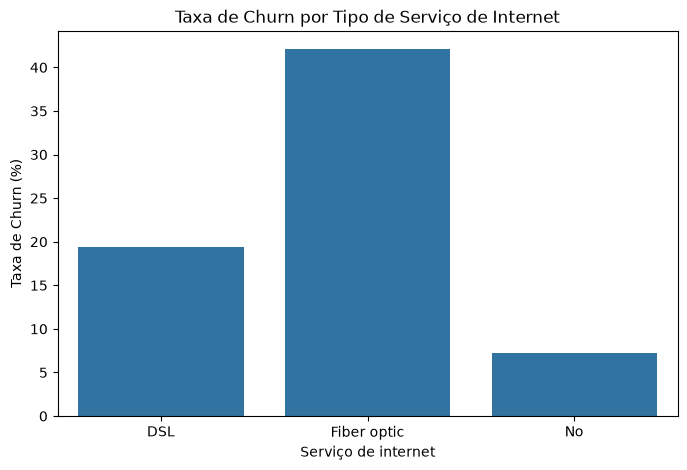

In [21]:
taxa = df_gold.groupby('serviçoDeInternet')['cancelamento'].apply(
    lambda x: x.mean() * 100
).reset_index(name='Taxa_Churn')

plt.figure(figsize=(8, 5))
sns.barplot(data=taxa, x='serviçoDeInternet', y='Taxa_Churn')

plt.title('Taxa de Churn por Tipo de Serviço de Internet')
plt.xlabel('Serviço de internet')
plt.ylabel('Taxa de Churn (%)')

plt.show()

#### Gênero

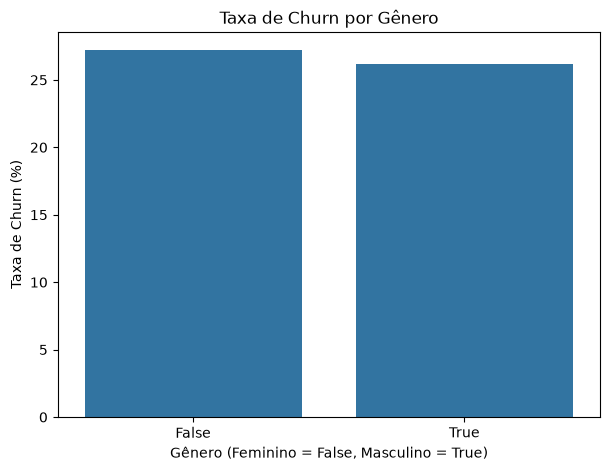

In [22]:
taxa = df_gold.groupby('genero')['cancelamento'].apply(
    lambda x: x.mean() * 100
).reset_index(name='Taxa_Churn')

plt.figure(figsize=(7, 5))
sns.barplot(data=taxa, x='genero', y='Taxa_Churn')

plt.title('Taxa de Churn por Gênero')
plt.xlabel('Gênero (Feminino = False, Masculino = True)')
plt.ylabel('Taxa de Churn (%)')

plt.show()

#### Perfil combinado
Clientes sem parceiro nem dependentes, com internet por fibra óptica e contrato mensal.

In [23]:

# Filtrar clientes com as características desejadas
filtro = df_gold[
    (df_gold['dependentes'] == False) &
    (df_gold['conjuge'] == False) &
    (df_gold['contrato'] == 'Month-to-month') &
    (df_gold['serviçoDeInternet'] == 'Fiber optic')
]

# Calcular quantidade de clientes com esse perfil
total_clientes = len(filtro)

# Calcular quantidade de cancelamentos desse perfil
cancelamentos = filtro['cancelamento'].sum()

# Calcular taxa de churn do perfil
taxa_churn_perfil = (cancelamentos / total_clientes) * 100 if total_clientes > 0 else 0.0

# Calcular total de cancelamentos da base inteira
total_cancelamentos = df_gold['cancelamento'].sum()

# Calcular representatividade nos cancelamentos totais
representatividade_cancelamentos = (
    (cancelamentos / total_cancelamentos) * 100
    if total_cancelamentos > 0 else 0.0
)

# Exibir resultados
print(f'Total de clientes com este perfil: {total_clientes}')
print(f'Cancelamentos deste perfil: {cancelamentos}')
print(f'Taxa de churn do perfil: {taxa_churn_perfil:.2f}%')
print(f'Representatividade nos cancelamentos totais: {representatividade_cancelamentos:.2f}%')

Total de clientes com este perfil: 966
Cancelamentos deste perfil: 556
Taxa de churn do perfil: 57.56%
Representatividade nos cancelamentos totais: 36.97%


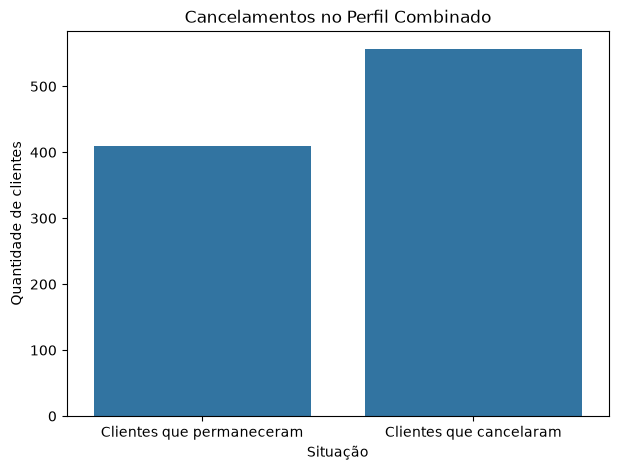

In [24]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=['Clientes que permaneceram', 'Clientes que cancelaram'],
    y=[
        total_clientes - cancelamentos,
        cancelamentos
    ]
)

plt.title('Cancelamentos no Perfil Combinado')
plt.ylabel('Quantidade de clientes')
plt.xlabel('Situação')

plt.show()

### Sentimento e cancelamento
Todos os clientes entram na comparação. Scores positivos e negativos entram integralmente no grupo correspondente, mesmo dentro da faixa que o VADER classifica como neutra. Um score exatamente zero contribui com 50% para cada grupo. Essa divisão é uma convenção da análise. As contagens, taxas e mensalidades dos gráficos usam esses pesos.

In [25]:
sns.set_theme(style="whitegrid")

COL_CHURN = "cancelamento"
COL_CONTRATO = "contrato"
COL_MENSAL = "mensalidade"

cores_sentimento = {"Positivo": "#2ecc71", "Negativo": "#e74c3c"}
ordem_sentimento = ["Positivo", "Negativo"]

score = df_gold["score_sentimento"]
peso_positivo = score.gt(0).astype(float) + 0.5 * score.eq(0)
df_sentimento = pd.concat([
    df_gold.assign(sentimento="Positivo", peso=peso_positivo),
    df_gold.assign(sentimento="Negativo", peso=1 - peso_positivo),
], ignore_index=True)
df_sentimento = df_sentimento.loc[df_sentimento["peso"].gt(0)].copy()
df_sentimento["peso_cancelamento"] = df_sentimento["peso"] * df_sentimento[COL_CHURN]
df_sentimento["mensalidade_ponderada"] = df_sentimento[COL_MENSAL] * df_sentimento["peso"]

totais_sentimento = df_sentimento.groupby("sentimento")["peso"].sum().reindex(
    ordem_sentimento, fill_value=0
)
print(f"Clientes na comparação: {len(df_gold)}")
print(f"Scores exatamente zero, divididos em 50/50: {score.eq(0).sum()}")
print(f"Participação positiva: {totais_sentimento['Positivo'] / len(df_gold):.1%}")
print(f"Participação negativa: {totais_sentimento['Negativo'] / len(df_gold):.1%}")

Clientes na comparação: 5634
Scores exatamente zero, divididos em 50/50: 6
Participação positiva: 87.9%
Participação negativa: 12.1%


### Distribuição ponderada do sentimento

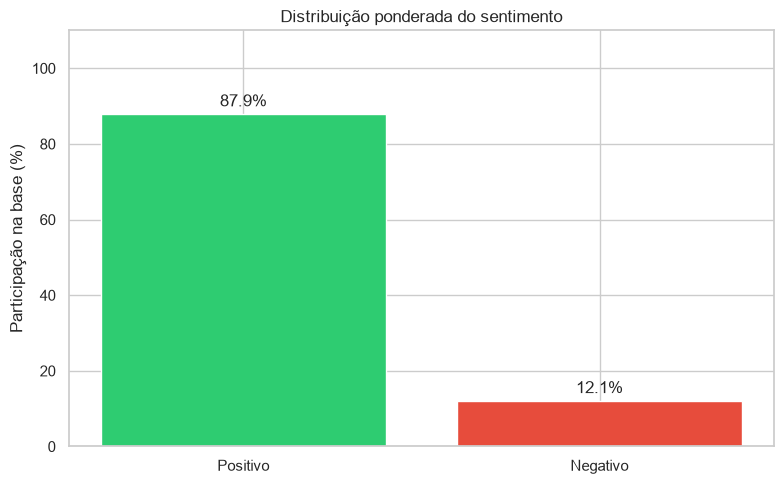

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
percentuais = totais_sentimento / len(df_gold) * 100
barras = ax.bar(ordem_sentimento, percentuais, color=[cores_sentimento[s] for s in ordem_sentimento])
ax.bar_label(barras, labels=[f"{valor:.1f}%" for valor in percentuais], padding=3)
ax.set_title("Distribuição ponderada do sentimento")
ax.set_ylabel("Participação na base (%)")
ax.set_ylim(0, 110)
fig.tight_layout()
plt.show()

### Taxa de cancelamento por sentimento
Em cada grupo, dividimos o peso dos clientes que cancelaram pelo peso total do grupo.

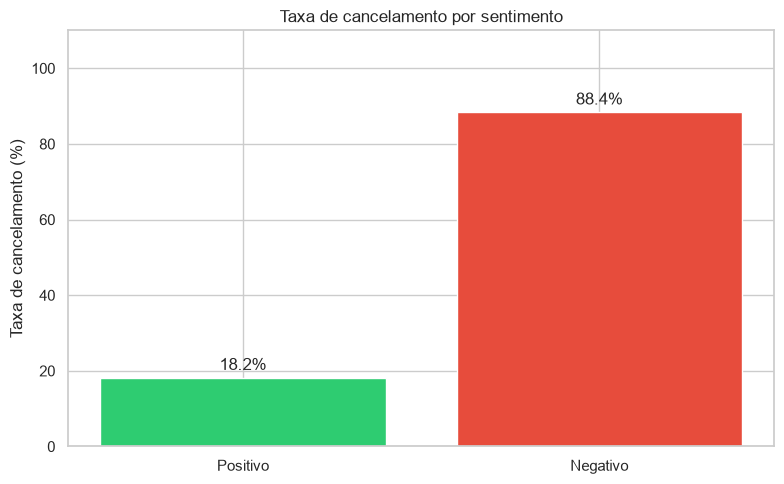

In [27]:
pesos_churn = df_sentimento.groupby("sentimento")[["peso", "peso_cancelamento"]].sum()
taxas = (100 * pesos_churn["peso_cancelamento"] / pesos_churn["peso"]).reindex(ordem_sentimento)
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(ordem_sentimento, taxas, color=[cores_sentimento[s] for s in ordem_sentimento])
ax.bar_label(barras, labels=[f"{taxa:.1f}%" if pd.notna(taxa) else "" for taxa in taxas], padding=3)
ax.set_title("Taxa de cancelamento por sentimento")
ax.set_ylabel("Taxa de cancelamento (%)")
ax.set_ylim(0, 110)
fig.tight_layout()
plt.show()

#### Composição de cancelamento por sentimento
Cada barra mostra as proporções de clientes que permaneceram e que cancelaram dentro daquele sentimento.

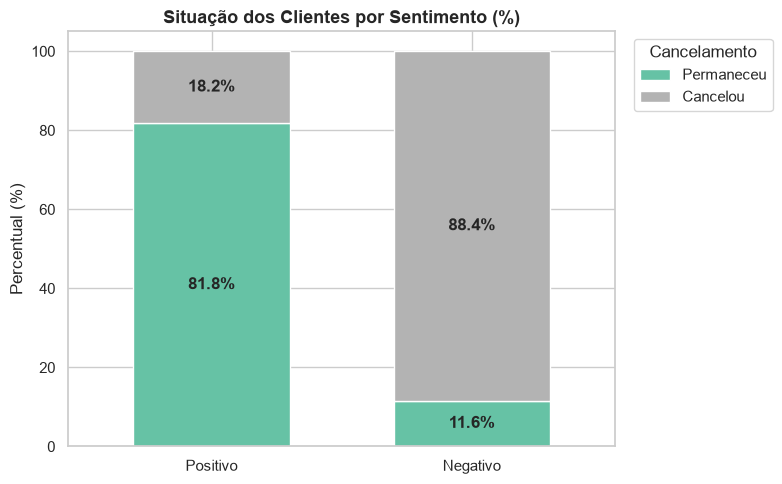

In [28]:
ct_churn = pd.crosstab(
    df_sentimento["sentimento"], df_sentimento[COL_CHURN],
    values=df_sentimento["peso"], aggfunc="sum", normalize="index",
).reindex(index=ordem_sentimento, columns=[False, True], fill_value=0).fillna(0) * 100
ct_churn.columns = ["Permaneceu", "Cancelou"]
ax = ct_churn.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2", width=0.6)

plt.title("Situação dos Clientes por Sentimento (%)", fontsize=13, fontweight="bold")
plt.xlabel("")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.legend(title="Cancelamento", bbox_to_anchor=(1.02, 1), loc="upper left")

for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Receita Mensal por Sentimento e Cancelamento

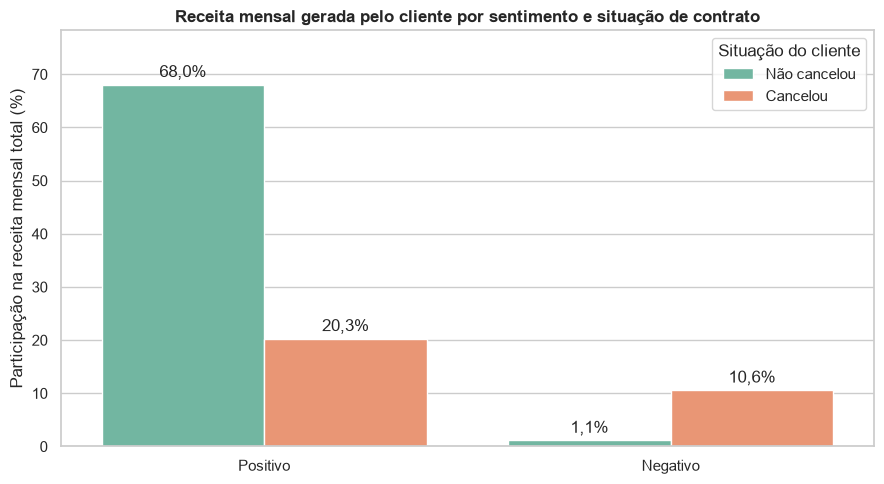

In [29]:
receita = (
    df_sentimento.groupby(["sentimento", COL_CHURN], observed=True)["mensalidade_ponderada"]
    .sum()
    .reset_index()
)

total_receita = receita["mensalidade_ponderada"].sum()
receita["percentual_receita"] = (
    receita["mensalidade_ponderada"] / total_receita * 100 if total_receita else 0.0
)
receita["situacao"] = receita[COL_CHURN].map({
    False: "Não cancelou",
    True: "Cancelou",
})

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=receita,
    x="sentimento",
    y="percentual_receita",
    hue="situacao",
    order=ordem_sentimento,
    hue_order=["Não cancelou", "Cancelou"],
    palette="Set2",
    ax=ax,
)

ax.set_title("Receita mensal gerada pelo cliente por sentimento e situação de contrato", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Participação na receita mensal total (%)")
ax.legend(title="Situação do cliente")
ax.margins(y=0.15)

for barra in ax.patches:
    percentual = barra.get_height()
    if percentual > 0:
        rotulo = f"{percentual:.1f}%".replace(".", ",")
        ax.annotate(
            rotulo,
            (barra.get_x() + barra.get_width() / 2, percentual),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
        )

fig.tight_layout()
plt.show()

### Sentimento como indicador de cancelamento
A regra associa sentimento negativo ao cancelamento e positivo à permanência. Um empate contribui com meia previsão para cada situação. A tabela usa contagens ponderadas e a referência usa o cancelamento observado de todos os clientes.

In [30]:
churn_real = df_gold[COL_CHURN]
situacoes = {False: "Não cancelou", True: "Cancelou"}
matriz_churn = pd.crosstab(
    df_sentimento[COL_CHURN].map(situacoes).rename("Observado"),
    df_sentimento["sentimento"].map({"Positivo": "Não cancelou", "Negativo": "Cancelou"}).rename("Previsto"),
    values=df_sentimento["peso"], aggfunc="sum",
).reindex(index=list(situacoes.values()), columns=list(situacoes.values()), fill_value=0).fillna(0)

acerto_churn = sum(matriz_churn.loc[situacao, situacao] for situacao in situacoes.values()) / len(df_gold)
referencia_churn = churn_real.value_counts(normalize=True).max()
print(f"Acerto ponderado da regra de churn: {acerto_churn:.1%}")
print(f"Acerto da previsão pela classe mais frequente: {referencia_churn:.1%}")
print(matriz_churn)

Acerto ponderado da regra de churn: 82.6%
Acerto da previsão pela classe mais frequente: 73.3%
Previsto      Não cancelou  Cancelou
Observado                           
Não cancelou        4051.0      79.0
Cancelou             902.0     602.0
